# NACA5D_05: Aerodynamic Coefficient Prediction

## Setup and Configuration

In [1]:
# Set TensorFlow logging and numerical options
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

In [2]:
# Load the libraries and configure the experiment
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from keras import Input, Sequential, backend, utils
from keras.callbacks import ReduceLROnPlateau
from keras.layers import Dense
from keras.metrics import RootMeanSquaredError
from keras.optimizers import Adam
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results").is_dir() and (p / "notebooks").is_dir()
)
N_RUNS = 20
EPOCHS = 50
TARGETS = ["CL", "CD", "Cm"]
DEPTH_ARCHITECTURES = ["M_64", "M_64_32", "M_64_32_16", "M_64_32_16_8"]
WIDTH_ARCHITECTURES = [
    "M_64_32_16",
    "M_128_64_32",
    "M_256_128_64",
    "M_512_256_128",
    "M_1024_512_256",
]
ARCHITECTURES = list(dict.fromkeys(DEPTH_ARCHITECTURES + WIDTH_ARCHITECTURES))


sys.path.insert(0, str(ROOT / "notebooks"))
experiment_results = __import__("experiment_results")
figure_output = __import__("figure_output")


def dataset_path(name):
    return experiment_results.dataset_path(ROOT, name)

In [3]:
# Format coefficient tables consistently
def style_table(table):
    return table.style.set_table_styles(
        [
            {"selector": "th", "props": [("text-align", "left")]},
            {"selector": "td", "props": [("text-align", "left")]},
        ]
    ).format(precision=6)


def show_table(table):
    display(style_table(table))


def model_index(names, case_numbers=None):
    numbers = (
        range(1, len(names) + 1)
        if case_numbers is None
        else [case_numbers[name] for name in names]
    )
    return pd.MultiIndex.from_tuples(
        [(number, architecture(name)) for number, name in zip(numbers, names)],
        names=["Case No.", "Network Architecture"],
    )


def metric_table(names, records, measures, case_numbers=None):
    columns = [f"{target}_{key}" for key, label in measures for target in TARGETS]
    table = pd.DataFrame([records[name].mean()[columns].to_numpy() for name in names])
    table.index = model_index(names, case_numbers)
    table.columns = pd.MultiIndex.from_tuples(
        [(label, target) for key, label in measures for target in TARGETS]
    )
    return table

In [4]:
# Style, save, and display the figures
plt.style.use("default")
plt.rcParams.update(
    {
        "figure.dpi": 160,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "0.35",
        "axes.linewidth": 0.7,
        "axes.axisbelow": True,
        "axes.formatter.use_mathtext": True,
        "grid.color": "0.88",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "figure.constrained_layout.use": True,
    }
)
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
NOTEBOOK_NAME = "NACA5D_05"
FIGURES = ROOT / "images" / NOTEBOOK_NAME
FIGURES.mkdir(parents=True, exist_ok=True)


def architecture(name):
    return "(" + name.removeprefix("M_").replace("_", "-") + "-3)"


def finish_figure(fig, filename, table=None, caption=None):
    figure_output.finish_figure(
        fig,
        FIGURES,
        filename,
        table=style_table(table) if table is not None else None,
        caption=caption,
    )


def plot_learning_curve(name, section, limits):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    for key, color, ls, label in [
        ("loss", "#332288", "-", "Training"),
        ("val_loss", "#CC6677", "--", "Validation"),
    ]:
        values = np.asarray([run[key] for run in histories[name]])
        epochs = np.arange(1, values.shape[1] + 1)
        ax.plot(
            epochs,
            np.median(values, axis=0),
            color=color,
            linestyle=ls,
            marker="D",
            markersize=2.5,
            markevery=np.flatnonzero(epochs % 10 == 0).tolist(),
            label=label,
        )
        if len(values) > 1:
            lo, hi = np.percentile(values, [10, 90], axis=0)
            ax.fill_between(epochs, lo, hi, color=color, alpha=0.12, linewidth=0)
    ax.set(
        xlabel="Epoch",
        ylabel="Mean squared error (MSE)",
        yscale="log",
    )
    ax.set_ylim(limits)
    last_epoch = max(len(run["loss"]) for runs in histories.values() for run in runs)
    last_tick = int(np.ceil(last_epoch / 10)) * 10
    ax.set_xlim(0, last_tick + 1)
    ax.set_xticks(np.arange(0, last_tick + 1, 10))
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
    ax.set_title(f"Architecture {architecture(name)}")
    ax.legend(loc="upper right")
    means = metrics[name].mean()
    table = pd.DataFrame(
        [[means[f"{target}_{key}"] for target in TARGETS] for key in ["rmse", "r2"]],
        index=pd.Index(["RMSE", "R²"], name="Metric"),
        columns=TARGETS,
    )
    layers = name.removeprefix("M_").replace("_", "-")
    finish_figure(
        fig,
        f"{section}-{layers}-mse",
        table=table,
        caption=f"Architecture {architecture(name)}. Mean squared error (MSE) is the "
        "squared prediction error averaged over samples and the three outputs "
        "(CL, CD, Cm), with equal weight for each output. Targets are unscaled; "
        "no target normalisation is applied. Curves show the median and "
        f"10–90% range across {N_RUNS} independent training runs (random seeds).",
    )


def learning_curve_limits():
    loss_values = np.concatenate(
        [
            np.asarray(run[key]).ravel()
            for runs in histories.values()
            for run in runs
            for key in ["loss", "val_loss"]
        ]
    )
    positive_losses = loss_values[np.isfinite(loss_values) & (loss_values > 0)]
    if not len(positive_losses):
        raise ValueError("Learning curves require positive finite losses")
    loss_limits = (
        10 ** np.floor(np.log10(positive_losses.min())),
        10 ** np.ceil(np.log10(positive_losses.max())),
    )
    if loss_limits[0] == loss_limits[1]:
        loss_limits = (loss_limits[0] / 10, loss_limits[1] * 10)
    return loss_limits


def show_learning_curve(name, section, limits=None):
    from IPython.utils.capture import capture_output

    if limits is None:
        limits = learning_curve_limits()
    with capture_output() as curve_output:
        plot_learning_curve(name, section, limits)
    content = HTML("".join(output.data["text/html"] for output in curve_output.outputs))
    key = (section, name)
    if key in learning_curve_displays:
        learning_curve_displays[key].update(content)
    else:
        learning_curve_displays[key] = display(content, display_id=True)

In [5]:
# Train seeded models and evaluate coefficient errors
learning_curve_displays = {}
histories = {}
models = {}
metrics = {}
validation_metrics = {}
test_predictions = {}


def make_reduce_lr():
    return ReduceLROnPlateau(monitor="val_loss", factor=0.9, patience=5, min_lr=0.00001)


def coefficient_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted, multioutput="raw_values")
    r2 = r2_score(actual, predicted, multioutput="raw_values")
    return {
        **{f"{target}_mse": mse[j] for j, target in enumerate(TARGETS)},
        **{f"{target}_rmse": np.sqrt(mse[j]) for j, target in enumerate(TARGETS)},
        **{f"{target}_r2": r2[j] for j, target in enumerate(TARGETS)},
    }


def train_architecture(name):
    if name in metrics:
        return
    hidden_layers = [int(size) for size in name.removeprefix("M_").split("_")]
    histories[name] = []
    run_metrics = []
    run_validation = []
    for i in range(N_RUNS):
        backend.clear_session()
        utils.set_random_seed(42 + i)
        print(f"Run {i + 1}/{N_RUNS} for model {architecture(name)}")
        model = Sequential(
            [Input(shape=(X_train.shape[1],))]
            + [Dense(size, activation="relu") for size in hidden_layers]
            + [Dense(len(TARGETS), activation="linear")]
        )
        model.compile(
            optimizer=Adam(learning_rate=5e-4, beta_1=0.9, beta_2=0.999),
            loss="mse",
            metrics=[RootMeanSquaredError()],
        )
        history = model.fit(
            X_train,
            y_train,
            epochs=EPOCHS,
            batch_size=128,
            validation_data=(X_val, y_val),
            callbacks=[make_reduce_lr()],
            verbose=0,
        )
        histories[name].append(history.history)
        predictions = model.predict(X_test, verbose=0)
        run_metrics.append(coefficient_metrics(y_test, predictions))
        run_validation.append(
            coefficient_metrics(y_val, model.predict(X_val, verbose=0))
        )
        if i == 0:
            models[name] = model
            test_predictions[name] = predictions
    metrics[name] = pd.DataFrame(run_metrics)
    validation_metrics[name] = pd.DataFrame(run_validation)

## Dataset Inspection

In [6]:
# Load and inspect the airfoil dataset
DATASETS = experiment_results.dataset_manifest(ROOT, ["NACA5D_05"])
df = pd.read_csv(dataset_path("NACA5D_05"))
show_table(df.head(10))
show_table(df.isnull().sum().to_frame("Missing Values"))
show_table(df.describe())

,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re,CL,CD,Cm
0,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-10.000000,0.100000,100000,-1.140000,0.024940,0.005000
1,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-9.000000,0.100000,100000,-1.027000,0.021160,0.004000
2,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-8.000000,0.100000,100000,-0.914000,0.016970,0.004000
3,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-7.000000,0.100000,100000,-0.800000,0.013640,0.003000
4,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-6.000000,0.100000,100000,-0.687000,0.024830,0.003000
5,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-5.000000,0.100000,100000,-0.572000,0.015650,0.002000
6,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-4.000000,0.100000,100000,-0.458000,0.011140,0.002000
7,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-3.000000,0.100000,100000,-0.344000,0.008820,0.001000
8,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-2.000000,0.100000,100000,-0.229000,0.013910,0.001000
9,5,0.000000,5,0,0.016694,0.024736,0.022058,0.013163,0.004284,-0.016694,-0.024736,-0.022058,-0.013163,-0.004284,-1.000000,0.100000,100000,-0.115000,0.013570,0.000000


,Missing Values
t,0
CL_design,0
p,0
s,0
yU1,0
yU2,0
yU3,0
yU4,0
yU5,0
yL1,0


,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re,CL,CD,Cm
count,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000,236880.000000
mean,19.960106,0.841223,27.632979,0.493351,0.096292,0.134144,0.111651,0.060456,0.017849,-0.034706,-0.063388,-0.066130,-0.045857,-0.016689,0.000000,0.200000,300000.000000,0.219178,0.025908,0.008664
std,10.003265,0.595420,16.860962,0.499957,0.047779,0.066417,0.059813,0.035302,0.011050,0.042542,0.065845,0.057175,0.033677,0.010987,6.055313,0.081650,141421.654747,0.925885,0.011283,0.092522
min,5.000000,0.000000,5.000000,0.000000,-0.004196,-0.034220,-0.048766,-0.048585,-0.021718,-0.150412,-0.221016,-0.208757,-0.158776,-0.062862,-10.000000,0.100000,100000.000000,-2.607000,0.002690,-0.169000
25%,10.000000,0.200000,15.000000,0.000000,0.060440,0.083429,0.066202,0.035288,0.009724,-0.064663,-0.113478,-0.110225,-0.069669,-0.024271,-5.000000,0.100000,200000.000000,-0.485000,0.018250,-0.031000
50%,20.000000,0.800000,25.000000,0.000000,0.094692,0.132999,0.110292,0.059885,0.017656,-0.030806,-0.064636,-0.066175,-0.045224,-0.016381,-0.000000,0.200000,300000.000000,0.218000,0.024650,-0.004000
75%,30.000000,1.400000,45.000000,1.000000,0.127479,0.179109,0.154377,0.086256,0.026085,-0.006198,-0.019232,-0.023071,-0.020494,-0.008568,5.000000,0.300000,400000.000000,0.928000,0.031580,0.018000
max,35.000000,1.800000,75.000000,1.000000,0.237894,0.331768,0.289322,0.160810,0.046274,0.077967,0.135837,0.101022,0.036191,0.008290,10.000000,0.300000,500000.000000,3.020000,0.617020,0.453000


In [7]:
# Shuffle rows and separate features from targets
df = df.sample(frac=1, random_state=42)
X = df.drop(columns=["t", "CL_design", "p", "s", "CL", "CD", "Cm"])
y = df[["CL", "CD", "Cm"]]
show_table(X.head(10))
show_table(y.head(10))

,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re
199415,0.102901,0.120570,0.074637,0.031086,0.006992,0.061349,0.070318,0.029936,0.004583,-0.001595,10.000000,0.100000,100000
170714,0.122161,0.180352,0.162866,0.098485,0.032845,-0.111751,-0.165987,-0.145928,-0.085791,-0.027096,-5.000000,0.300000,500000
124850,0.035215,0.054127,0.049706,0.030296,0.010348,-0.031580,-0.044820,-0.038526,-0.022358,-0.006787,-5.000000,0.200000,100000
21252,0.083475,0.123684,0.110299,0.065822,0.021423,-0.083468,-0.123672,-0.110285,-0.065812,-0.021419,-10.000000,0.100000,300000
112657,0.131996,0.171434,0.139094,0.076427,0.023158,-0.025738,-0.075789,-0.083729,-0.056754,-0.020125,3.000000,0.200000,500000
121812,0.160036,0.232121,0.213201,0.120435,0.032418,-0.067714,-0.114019,-0.097790,-0.067368,-0.028090,2.000000,0.100000,100000
218986,0.194877,0.209262,0.130355,0.031141,0.002004,-0.012972,-0.145138,-0.193962,-0.158776,-0.062862,9.000000,0.100000,300000
186741,0.080807,0.151814,0.141138,0.066655,0.011340,0.006241,0.051692,0.051732,0.012219,-0.005906,-1.000000,0.300000,300000
83458,0.084891,0.116334,0.100773,0.059205,0.018938,-0.041630,-0.080973,-0.076642,-0.046913,-0.015588,-6.000000,0.200000,500000
229247,0.117893,0.191172,0.176628,0.099499,0.029871,-0.023324,-0.007971,-0.001724,-0.007926,-0.004997,1.000000,0.300000,200000


,CL,CD,Cm
199415,1.677000,0.035930,0.014000
170714,-0.631000,0.031710,-0.008000
124850,-0.549000,0.018570,-0.009000
21252,-1.331000,0.032310,0.018000
112657,0.759000,0.024260,0.020000
121812,0.852000,0.039250,-0.044000
218986,0.281000,0.019380,0.434000
186741,0.580000,0.017610,-0.082000
83458,-0.609000,0.011550,0.006000
229247,1.220000,0.029730,-0.162000


## Data Splitting and Feature Scaling

Rows are split into 70% training, 15% validation, and 15% test. Every test row in the saved run has the same surface coordinates as a training row. These scores measure prediction at held-out flight-condition rows for geometries seen during training.

In [8]:
# Split the data into 70% training, 15% validation, and 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, train_size=0.7, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Show sample counts and fractions for each split
split_summary = pd.DataFrame(
    {
        "Samples": [len(X_train), len(X_val), len(X_test)],
        "Fraction": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    },
    index=pd.Index(["Training", "Validation", "Test"], name="Split"),
)
show_table(split_summary)

,Samples,Fraction
Split,,
Training,165816,0.700000
Validation,35532,0.150000
Test,35532,0.150000


In [9]:
# Scale features using training statistics only
X_scaler = StandardScaler()
X_train = pd.DataFrame(
    X_scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_val = pd.DataFrame(X_scaler.transform(X_val), columns=X.columns, index=X_val.index)
X_test = pd.DataFrame(X_scaler.transform(X_test), columns=X.columns, index=X_test.index)

In [10]:
# Inspect scaled features and physical coefficient targets
for features, targets in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]:
    show_table(features.head())
    show_table(targets.head())

,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re
222650,1.603276,1.122147,0.675899,0.421024,0.256311,1.172132,1.084686,0.651938,0.405743,0.237177,-0.332562,-0.001041,0.002618
70926,-0.894934,-0.736164,-0.760277,-0.806162,-0.844794,0.471871,0.751996,0.763219,0.742224,0.729653,-0.167599,-1.225316,0.002618
146567,-1.618488,-1.557300,-1.378654,-1.197106,-1.024478,0.471834,0.673833,0.891688,1.115786,1.328161,-0.332562,-0.001041,1.416559
204708,0.910114,1.241670,0.782573,0.089868,-0.469389,1.159043,2.004808,1.501318,0.843213,0.315615,-1.652265,1.223234,0.709588
141608,0.806749,0.989158,1.182546,1.297089,1.392283,-0.673830,-0.513100,-0.305056,-0.216351,-0.166010,-0.827451,-0.001041,0.709588


,CL,CD,Cm
222650,0.445000,0.022380,0.024000
70926,0.037000,0.014740,0.004000
146567,-0.165000,0.011010,-0.015000
204708,-0.633000,0.072350,-0.002000
141608,-0.044000,0.026290,-0.075000


,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re
3134,-0.964316,-0.900341,-0.758760,-0.592832,-0.451399,-0.361800,-0.165168,-0.002014,0.187245,0.346839,-0.827451,-0.001041,1.416559
129610,0.089944,-0.633331,-1.120137,-1.561682,-1.780463,0.897239,0.070707,-0.407464,-0.845409,-1.037233,1.482029,-0.001041,-0.704353
165341,0.386784,0.794885,1.026232,0.829464,0.183661,0.214337,0.774786,1.060700,0.805145,0.180508,-0.332562,1.223234,0.709588
201636,-0.303878,0.121756,-0.089954,-0.144306,-0.202985,1.774767,2.369379,2.229526,2.208221,2.143515,0.822178,-0.001041,-0.704353
70640,-1.269786,-1.108060,-1.132300,-1.181953,-1.232857,0.847106,1.127429,1.147438,1.130814,1.118715,1.152103,-1.225316,0.709588


,CL,CD,Cm
3134,-0.631000,0.016850,0.006000
129610,0.624000,0.008210,0.233000
165341,0.432000,0.024360,-0.067000
201636,1.514000,0.003110,-0.121000
70640,0.947000,0.007530,-0.002000


,yU1,yU2,yU3,yU4,yU5,yL1,yL2,yL3,yL4,yL5,alpha,M,Re
144349,-1.864476,-2.033350,-1.986789,-1.852917,-1.689945,0.189232,0.192209,0.255118,0.426841,0.657241,0.987141,-1.225316,0.709588
233858,-0.803326,-0.857992,-0.912463,-0.807980,-0.565286,-1.778924,-1.638362,-1.710153,-1.631356,-1.357582,-1.322339,-0.001041,-0.704353
86433,0.776096,0.718637,0.574815,0.352180,0.246816,0.443544,-1.504050,-1.790262,-2.063399,-2.196140,1.317066,-1.225316,-1.411323
128139,0.313182,0.278342,0.341331,0.481236,0.616022,0.004386,-0.455674,-0.436153,-0.311080,-0.196860,1.317066,1.223234,-0.704353
37200,0.483534,0.669122,0.794150,0.974038,1.168667,-1.678082,-1.573705,-1.481204,-1.323078,-1.167081,-0.167599,-1.225316,-0.704353


,CL,CD,Cm
144349,0.362000,0.011500,0.067000
233858,-1.823000,0.040130,0.145000
86433,0.797000,0.033600,0.145000
128139,1.440000,0.037050,-0.008000
37200,-0.075000,0.031620,0.003000


## Network Depth Experiments

### Case 1: Model (64-3)

Run 1/20 for model (64-3)
Run 2/20 for model (64-3)
Run 3/20 for model (64-3)
Run 4/20 for model (64-3)
Run 5/20 for model (64-3)
Run 6/20 for model (64-3)
Run 7/20 for model (64-3)
Run 8/20 for model (64-3)
Run 9/20 for model (64-3)
Run 10/20 for model (64-3)
Run 11/20 for model (64-3)
Run 12/20 for model (64-3)
Run 13/20 for model (64-3)
Run 14/20 for model (64-3)
Run 15/20 for model (64-3)
Run 16/20 for model (64-3)
Run 17/20 for model (64-3)
Run 18/20 for model (64-3)
Run 19/20 for model (64-3)
Run 20/20 for model (64-3)


,CL,CD,Cm
Metric,,,
RMSE,0.004857,0.005532,0.002370
R²,0.999972,0.740250,0.999340

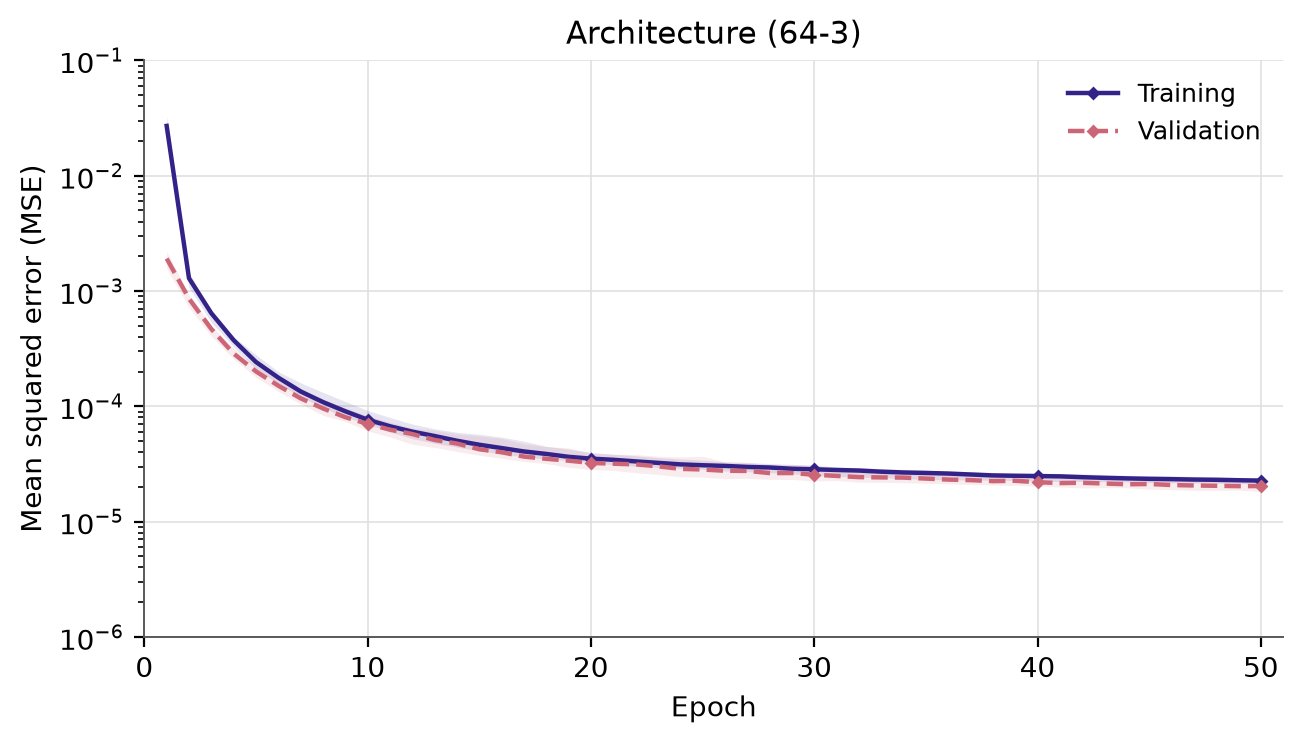

In [11]:
# Evaluate the single-hidden-layer baseline
train_architecture(DEPTH_ARCHITECTURES[0])
show_learning_curve(DEPTH_ARCHITECTURES[0], "depth")

### Case 2: Model (64-32-3)

Run 1/20 for model (64-32-3)
Run 2/20 for model (64-32-3)
Run 3/20 for model (64-32-3)
Run 4/20 for model (64-32-3)
Run 5/20 for model (64-32-3)
Run 6/20 for model (64-32-3)
Run 7/20 for model (64-32-3)
Run 8/20 for model (64-32-3)
Run 9/20 for model (64-32-3)
Run 10/20 for model (64-32-3)
Run 11/20 for model (64-32-3)
Run 12/20 for model (64-32-3)
Run 13/20 for model (64-32-3)
Run 14/20 for model (64-32-3)
Run 15/20 for model (64-32-3)
Run 16/20 for model (64-32-3)
Run 17/20 for model (64-32-3)
Run 18/20 for model (64-32-3)
Run 19/20 for model (64-32-3)
Run 20/20 for model (64-32-3)


,CL,CD,Cm
Metric,,,
RMSE,0.003793,0.005204,0.001990
R²,0.999983,0.770384,0.999534

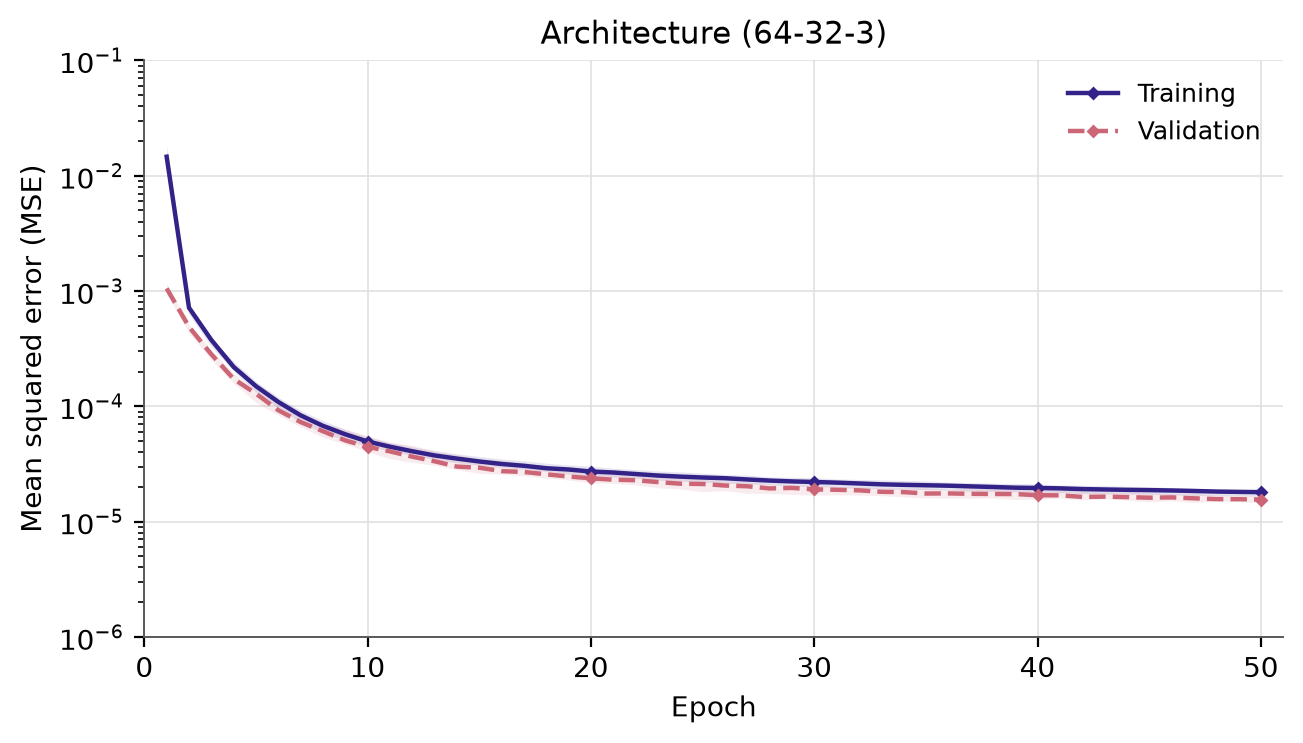

In [12]:
# Evaluate the network with two hidden layers
train_architecture(DEPTH_ARCHITECTURES[1])
show_learning_curve(DEPTH_ARCHITECTURES[1], "depth")

### Case 3: Model (64-32-16-3)

Run 1/20 for model (64-32-16-3)
Run 2/20 for model (64-32-16-3)
Run 3/20 for model (64-32-16-3)
Run 4/20 for model (64-32-16-3)
Run 5/20 for model (64-32-16-3)
Run 6/20 for model (64-32-16-3)
Run 7/20 for model (64-32-16-3)
Run 8/20 for model (64-32-16-3)
Run 9/20 for model (64-32-16-3)
Run 10/20 for model (64-32-16-3)
Run 11/20 for model (64-32-16-3)
Run 12/20 for model (64-32-16-3)
Run 13/20 for model (64-32-16-3)
Run 14/20 for model (64-32-16-3)
Run 15/20 for model (64-32-16-3)
Run 16/20 for model (64-32-16-3)
Run 17/20 for model (64-32-16-3)
Run 18/20 for model (64-32-16-3)
Run 19/20 for model (64-32-16-3)
Run 20/20 for model (64-32-16-3)


,CL,CD,Cm
Metric,,,
RMSE,0.003910,0.005153,0.001951
R²,0.999982,0.774706,0.999552

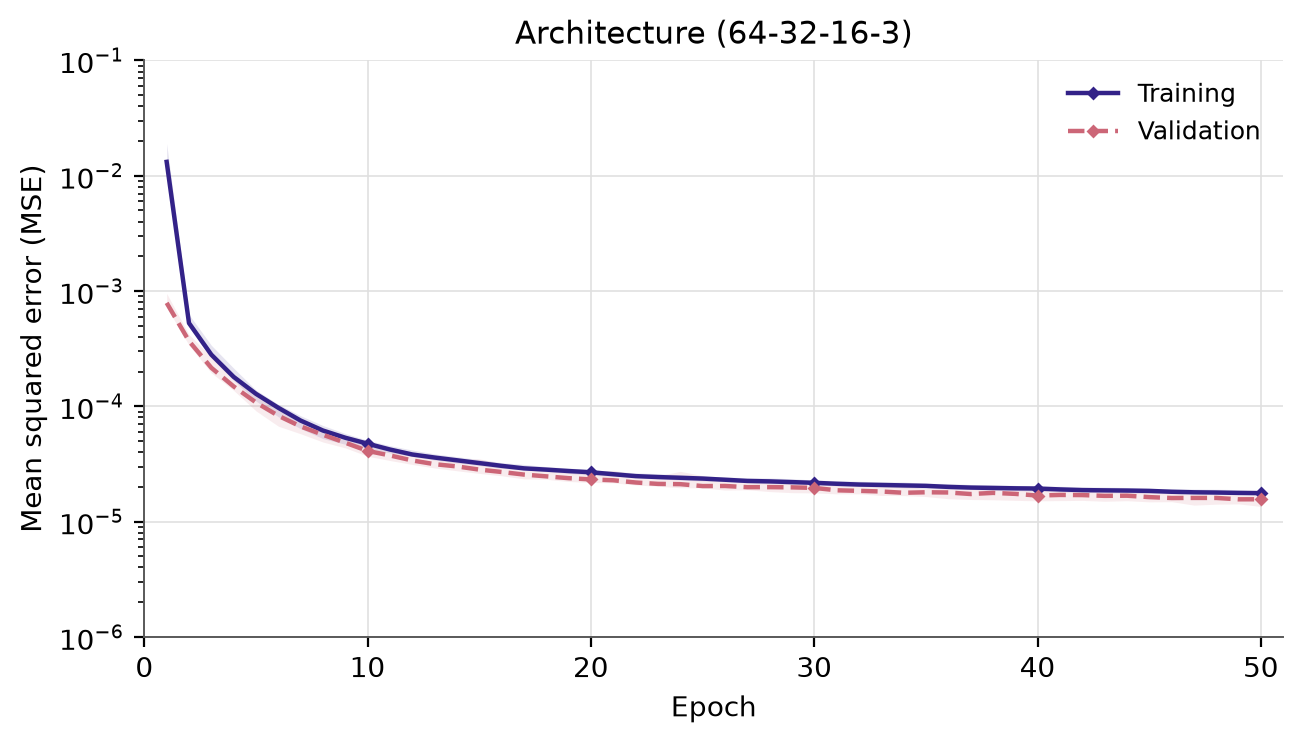

In [13]:
# Evaluate the network with three hidden layers
train_architecture(DEPTH_ARCHITECTURES[2])
show_learning_curve(DEPTH_ARCHITECTURES[2], "depth")

### Case 4: Model (64-32-16-8-3)

Run 1/20 for model (64-32-16-8-3)
Run 2/20 for model (64-32-16-8-3)
Run 3/20 for model (64-32-16-8-3)
Run 4/20 for model (64-32-16-8-3)
Run 5/20 for model (64-32-16-8-3)
Run 6/20 for model (64-32-16-8-3)
Run 7/20 for model (64-32-16-8-3)
Run 8/20 for model (64-32-16-8-3)
Run 9/20 for model (64-32-16-8-3)
Run 10/20 for model (64-32-16-8-3)
Run 11/20 for model (64-32-16-8-3)
Run 12/20 for model (64-32-16-8-3)
Run 13/20 for model (64-32-16-8-3)
Run 14/20 for model (64-32-16-8-3)
Run 15/20 for model (64-32-16-8-3)
Run 16/20 for model (64-32-16-8-3)
Run 17/20 for model (64-32-16-8-3)
Run 18/20 for model (64-32-16-8-3)
Run 19/20 for model (64-32-16-8-3)
Run 20/20 for model (64-32-16-8-3)


,CL,CD,Cm
Metric,,,
RMSE,0.003965,0.005241,0.002016
R²,0.999981,0.765972,0.999522

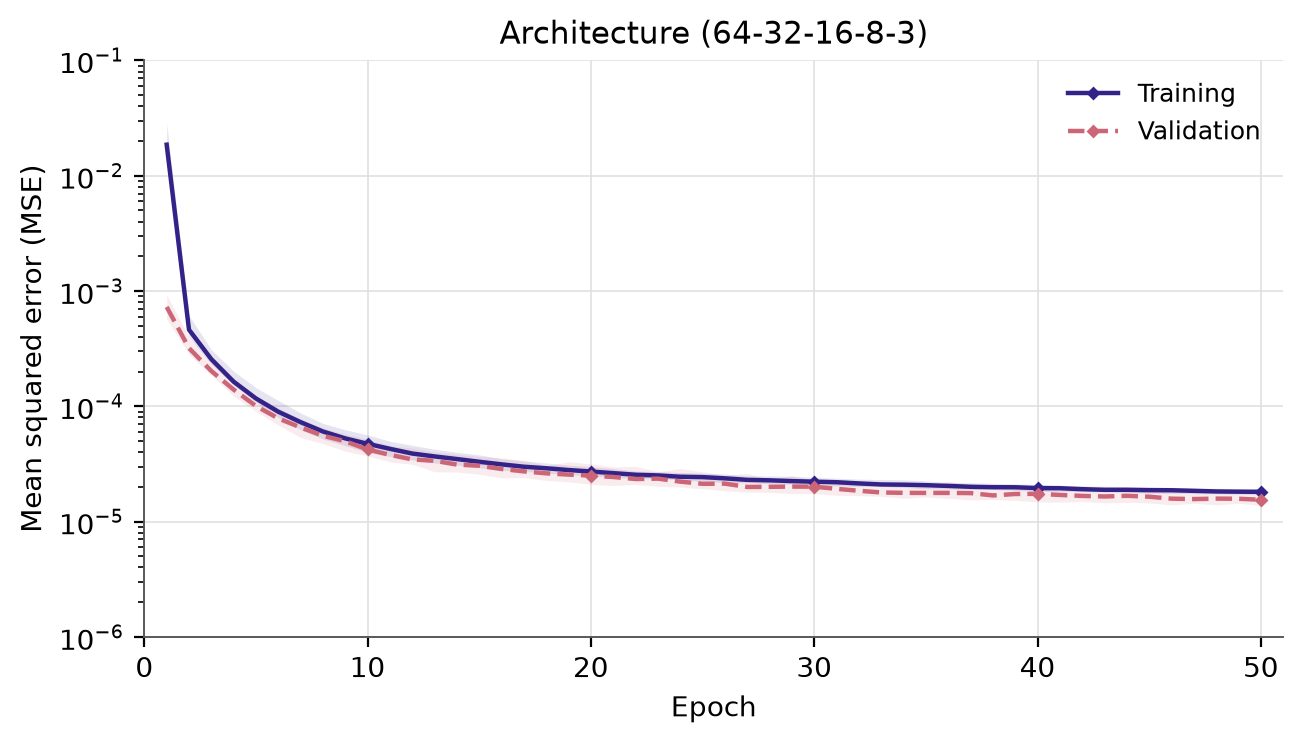

In [14]:
# Evaluate the network with four hidden layers
train_architecture(DEPTH_ARCHITECTURES[3])
show_learning_curve(DEPTH_ARCHITECTURES[3], "depth")

### Depth Comparison

In [15]:
# Compare mean test RMSE and R² across network depths
show_table(metric_table(DEPTH_ARCHITECTURES, metrics, [("rmse", "RMSE"), ("r2", "R²")]))

## Network Width Experiments

### Case 1: Model (64-32-16-3)

,CL,CD,Cm
Metric,,,
RMSE,0.003910,0.005153,0.001951
R²,0.999982,0.774706,0.999552

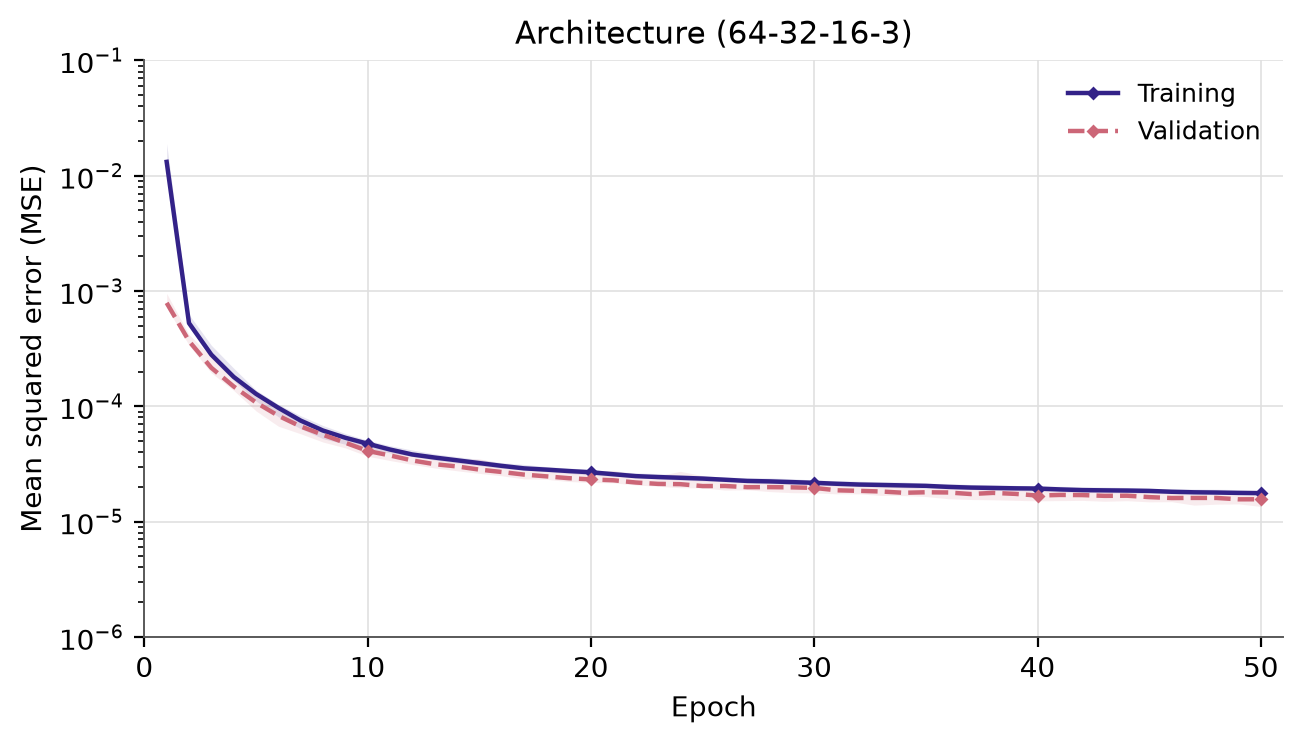

In [16]:
# Reuse the 64-32-16 network as the width baseline
train_architecture(WIDTH_ARCHITECTURES[0])
show_learning_curve(WIDTH_ARCHITECTURES[0], "width")

### Case 2: Model (128-64-32-3)

Run 1/20 for model (128-64-32-3)
Run 2/20 for model (128-64-32-3)
Run 3/20 for model (128-64-32-3)
Run 4/20 for model (128-64-32-3)
Run 5/20 for model (128-64-32-3)
Run 6/20 for model (128-64-32-3)
Run 7/20 for model (128-64-32-3)
Run 8/20 for model (128-64-32-3)
Run 9/20 for model (128-64-32-3)
Run 10/20 for model (128-64-32-3)
Run 11/20 for model (128-64-32-3)
Run 12/20 for model (128-64-32-3)
Run 13/20 for model (128-64-32-3)
Run 14/20 for model (128-64-32-3)
Run 15/20 for model (128-64-32-3)
Run 16/20 for model (128-64-32-3)
Run 17/20 for model (128-64-32-3)
Run 18/20 for model (128-64-32-3)
Run 19/20 for model (128-64-32-3)
Run 20/20 for model (128-64-32-3)


,CL,CD,Cm
Metric,,,
RMSE,0.002854,0.004674,0.001354
R²,0.999990,0.814288,0.999783

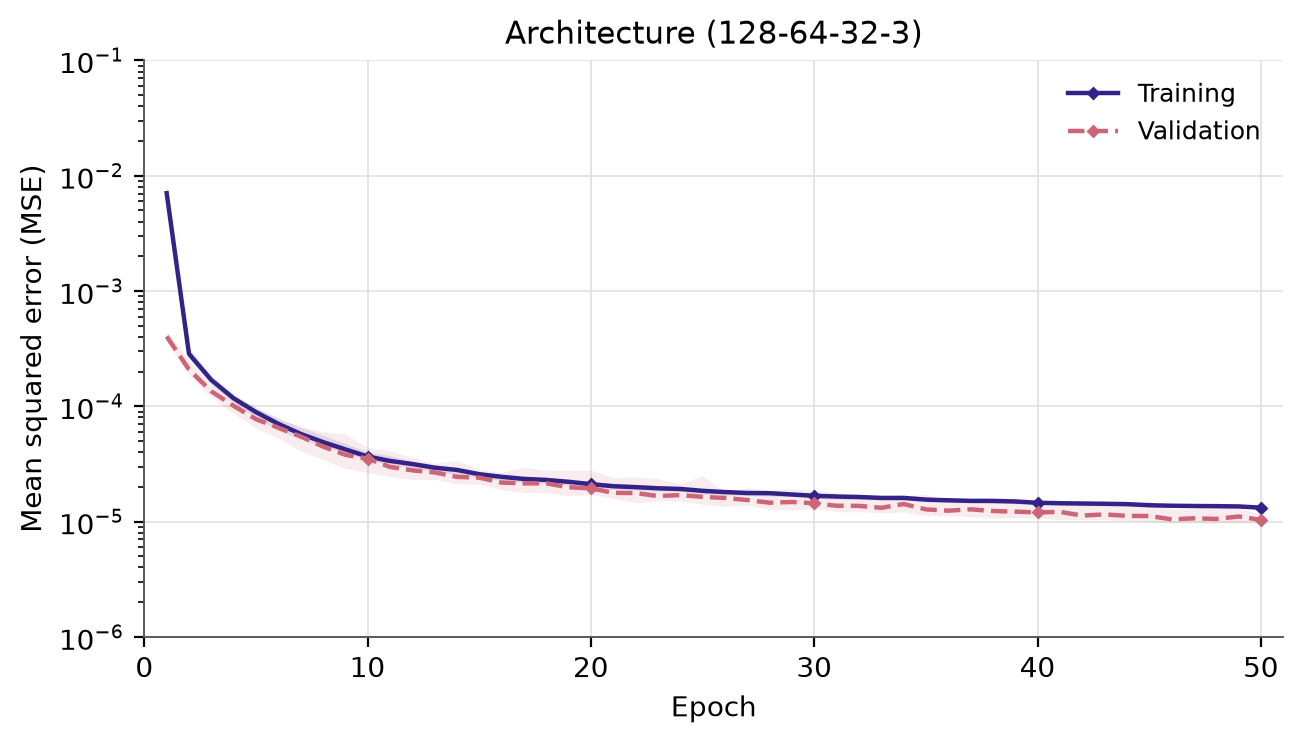

In [17]:
# Evaluate hidden-layer widths of 128, 64, and 32 neurons
train_architecture(WIDTH_ARCHITECTURES[1])
show_learning_curve(WIDTH_ARCHITECTURES[1], "width")

### Case 3: Model (256-128-64-3)

Run 1/20 for model (256-128-64-3)
Run 2/20 for model (256-128-64-3)
Run 3/20 for model (256-128-64-3)
Run 4/20 for model (256-128-64-3)
Run 5/20 for model (256-128-64-3)
Run 6/20 for model (256-128-64-3)
Run 7/20 for model (256-128-64-3)
Run 8/20 for model (256-128-64-3)
Run 9/20 for model (256-128-64-3)
Run 10/20 for model (256-128-64-3)
Run 11/20 for model (256-128-64-3)
Run 12/20 for model (256-128-64-3)
Run 13/20 for model (256-128-64-3)
Run 14/20 for model (256-128-64-3)
Run 15/20 for model (256-128-64-3)
Run 16/20 for model (256-128-64-3)
Run 17/20 for model (256-128-64-3)
Run 18/20 for model (256-128-64-3)
Run 19/20 for model (256-128-64-3)
Run 20/20 for model (256-128-64-3)


,CL,CD,Cm
Metric,,,
RMSE,0.002482,0.004347,0.001097
R²,0.999992,0.838808,0.999857

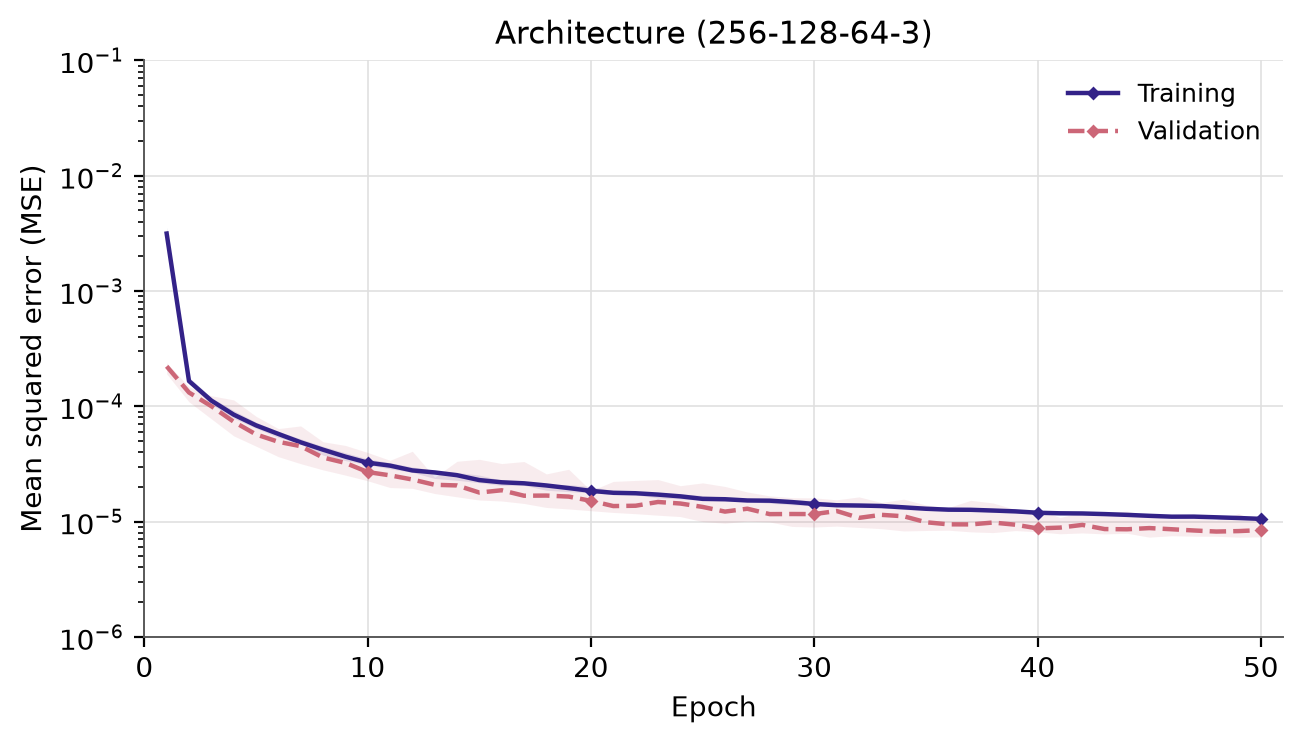

In [18]:
# Evaluate hidden-layer widths of 256, 128, and 64 neurons
train_architecture(WIDTH_ARCHITECTURES[2])
show_learning_curve(WIDTH_ARCHITECTURES[2], "width")

### Case 4: Model (512-256-128-3)

Run 1/20 for model (512-256-128-3)
Run 2/20 for model (512-256-128-3)
Run 3/20 for model (512-256-128-3)
Run 4/20 for model (512-256-128-3)
Run 5/20 for model (512-256-128-3)
Run 6/20 for model (512-256-128-3)
Run 7/20 for model (512-256-128-3)
Run 8/20 for model (512-256-128-3)
Run 9/20 for model (512-256-128-3)
Run 10/20 for model (512-256-128-3)
Run 11/20 for model (512-256-128-3)
Run 12/20 for model (512-256-128-3)
Run 13/20 for model (512-256-128-3)
Run 14/20 for model (512-256-128-3)
Run 15/20 for model (512-256-128-3)
Run 16/20 for model (512-256-128-3)
Run 17/20 for model (512-256-128-3)
Run 18/20 for model (512-256-128-3)
Run 19/20 for model (512-256-128-3)
Run 20/20 for model (512-256-128-3)


,CL,CD,Cm
Metric,,,
RMSE,0.002239,0.004187,0.000963
R²,0.999994,0.850527,0.999888

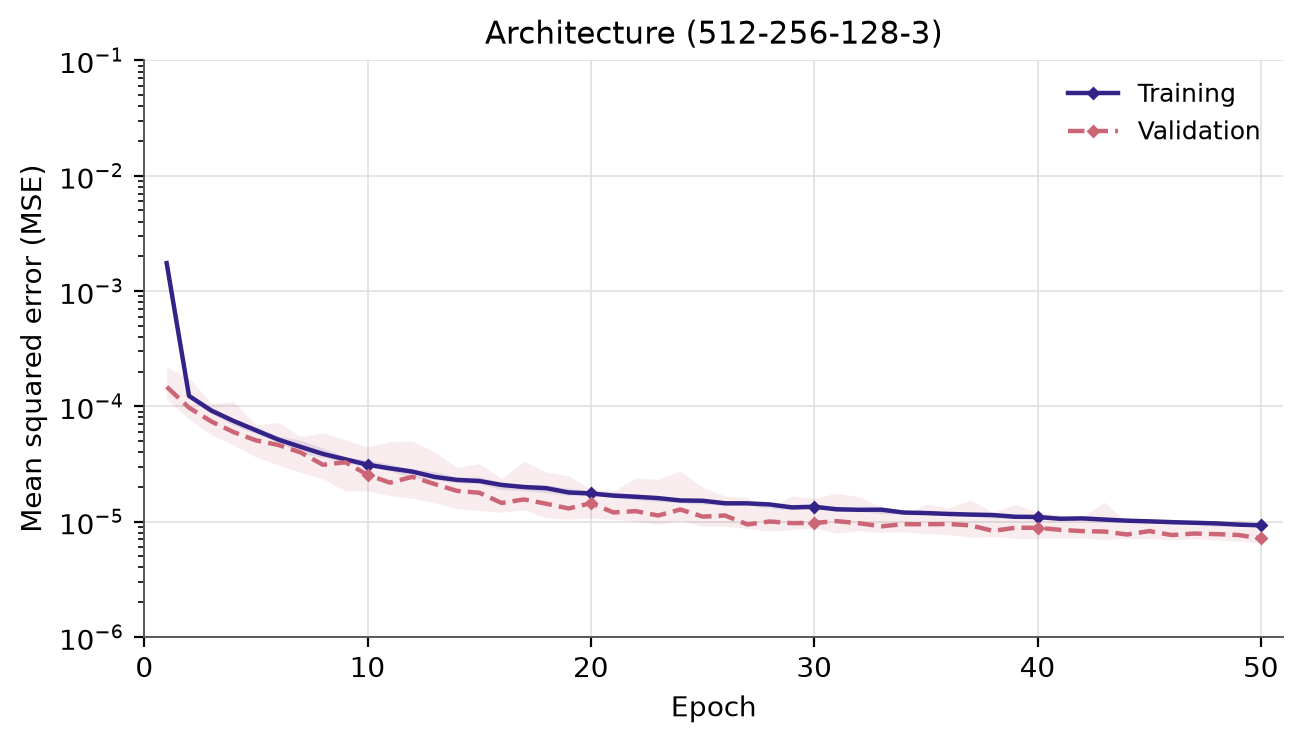

In [19]:
# Evaluate hidden-layer widths of 512, 256, and 128 neurons
train_architecture(WIDTH_ARCHITECTURES[3])
show_learning_curve(WIDTH_ARCHITECTURES[3], "width")

### Case 5: Model (1024-512-256-3)

Run 1/20 for model (1024-512-256-3)
Run 2/20 for model (1024-512-256-3)
Run 3/20 for model (1024-512-256-3)
Run 4/20 for model (1024-512-256-3)
Run 5/20 for model (1024-512-256-3)
Run 6/20 for model (1024-512-256-3)
Run 7/20 for model (1024-512-256-3)
Run 8/20 for model (1024-512-256-3)
Run 9/20 for model (1024-512-256-3)
Run 10/20 for model (1024-512-256-3)
Run 11/20 for model (1024-512-256-3)
Run 12/20 for model (1024-512-256-3)
Run 13/20 for model (1024-512-256-3)
Run 14/20 for model (1024-512-256-3)
Run 15/20 for model (1024-512-256-3)
Run 16/20 for model (1024-512-256-3)
Run 17/20 for model (1024-512-256-3)
Run 18/20 for model (1024-512-256-3)
Run 19/20 for model (1024-512-256-3)
Run 20/20 for model (1024-512-256-3)


,CL,CD,Cm
Metric,,,
RMSE,0.002345,0.004190,0.000921
R²,0.999993,0.849926,0.999900

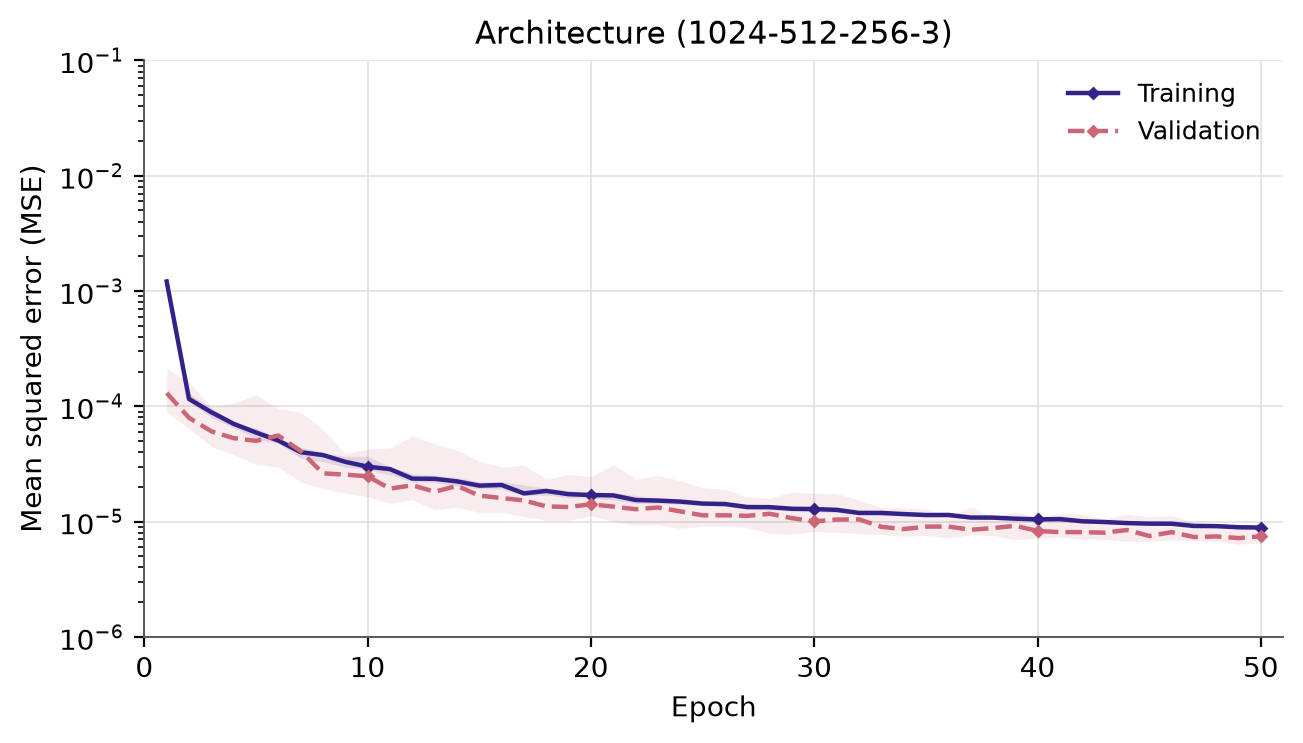

In [20]:
# Evaluate hidden-layer widths of 1024, 512, and 256 neurons
train_architecture(WIDTH_ARCHITECTURES[4])
show_learning_curve(WIDTH_ARCHITECTURES[4], "width")

### Width Comparison

In [21]:
# Compare mean test RMSE and R² across network widths
show_table(metric_table(WIDTH_ARCHITECTURES, metrics, [("rmse", "RMSE"), ("r2", "R²")]))

## Model Selection and Evaluation

### Validation Ranking

In [22]:
# Rank architectures by normalized validation error
training_variance = np.var(np.asarray(y_train), axis=0, ddof=0)
if np.any(training_variance <= 0):
    raise ValueError("Each target must have nonzero training-set variance")
validation_scores = []
for name, runs in validation_metrics.items():
    normalized_mse = (
        runs[[f"{target}_mse" for target in TARGETS]].to_numpy() / training_variance
    )
    validation_scores.append(
        {
            "Architecture": name,
            "Score": normalized_mse.mean(),
            **{target: normalized_mse[:, j].mean() for j, target in enumerate(TARGETS)},
            "Parameters": models[name].count_params(),
        }
    )

validation_ranking = (
    pd.DataFrame(validation_scores)
    .sort_values(["Score", "Parameters", "Architecture"])
    .reset_index(drop=True)
)
ranked_names = validation_ranking["Architecture"].tolist()
selected_architecture = ranked_names[0]
case_numbers = {name: i for i, name in enumerate(histories, start=1)}
selection_table = validation_ranking[["CL", "CD", "Cm", "Score", "Parameters"]].copy()
selection_table.index = model_index(ranked_names, case_numbers)
selection_table.columns = pd.MultiIndex.from_tuples(
    [("Normalized MSE", target) for target in TARGETS]
    + [("Normalized MSE", "Mean"), ("Model", "Parameters")]
)
print("Validation selection scores (lower is better)")
show_table(selection_table)
print("Validation MSE and R² (mean across seeded runs)")
validation_details = metric_table(
    ranked_names, validation_metrics, [("mse", "MSE"), ("r2", "R²")], case_numbers
)
validation_details[("R²", "Mean")] = validation_details["R²"].mean(axis=1)
show_table(validation_details)
print(f"Selected architecture: {architecture(selected_architecture)}")

Validation selection scores (lower is better)


Validation MSE and R² (mean across seeded runs)


Selected architecture: (1024-512-256-3)


### Held-Out Row Test Results

In [23]:
# Report test scores for the validation-selected architecture
y_final = test_predictions[selected_architecture]
print(
    f"Test performance for {architecture(selected_architecture)} (mean across seeded runs)"
)
selected_test_results = metric_table(
    [selected_architecture], metrics, [("mse", "MSE"), ("r2", "R²")], case_numbers
)
show_table(selected_test_results)

Test performance for (1024-512-256-3) (mean across seeded runs)


### Target vs Predicted Coefficients

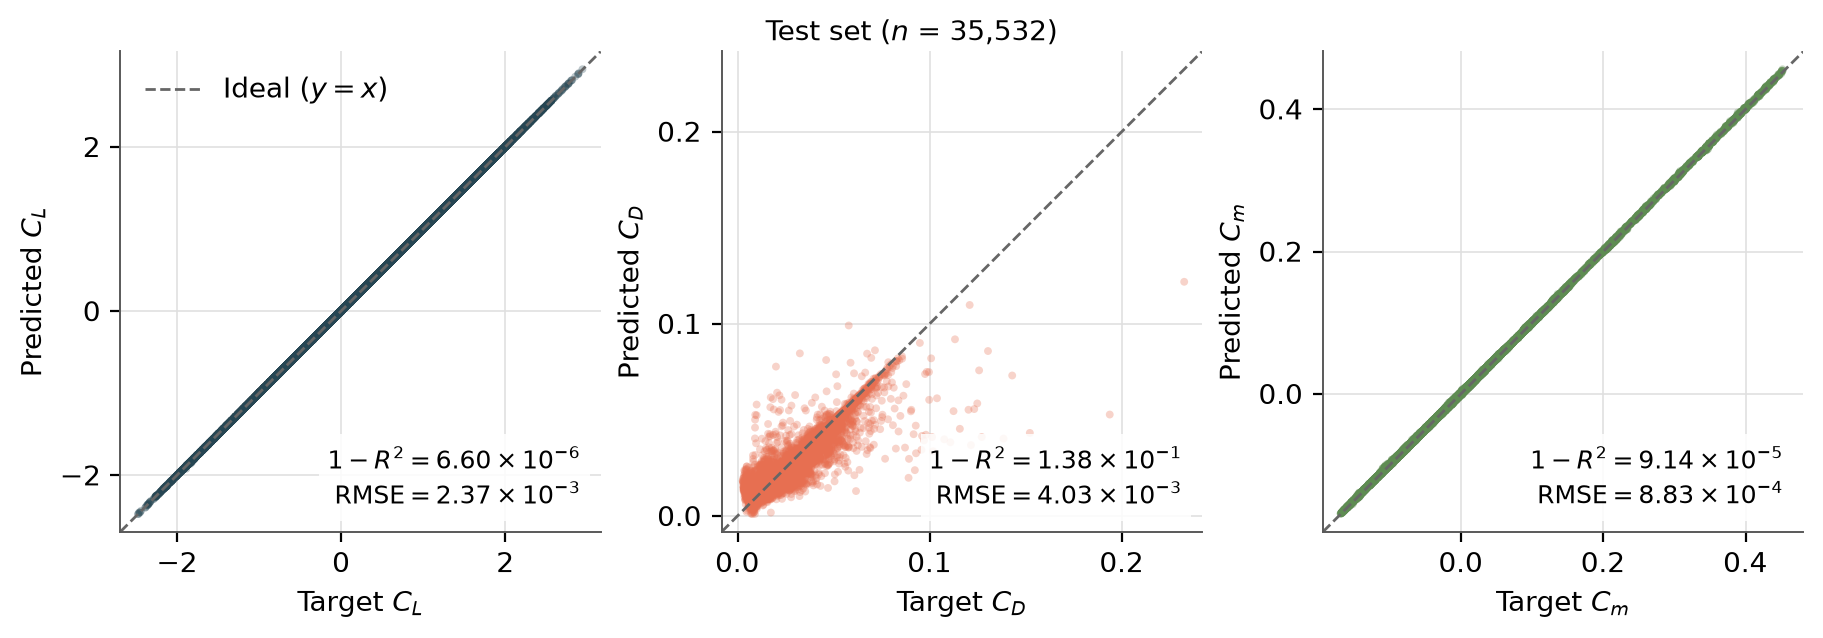

In [24]:
# Compare actual and predicted coefficients for the fixed-seed run
def scientific_notation(value):
    if value == 0:
        return "0"
    mantissa, exponent = f"{value:.2e}".split("e")
    return rf"{mantissa} \times 10^{{{int(exponent)}}}"


actual = np.asarray(y_test)
parity_rmse = np.sqrt(mean_squared_error(actual, y_final, multioutput="raw_values"))
parity_r2 = r2_score(actual, y_final, multioutput="raw_values")
fig, axes = plt.subplots(1, 3, figsize=(9, 3.1))
for j, (ax, target, color) in enumerate(
    zip(axes, [r"$C_L$", r"$C_D$", r"$C_m$"], ["#264653", "#E76F51", "#5E8C52"])
):
    low = min(actual[:, j].min(), y_final[:, j].min())
    high = max(actual[:, j].max(), y_final[:, j].max())
    pad = max((high - low) * 0.04, 1e-6)
    locator = MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10])
    ticks = locator.tick_values(low - pad, high + pad)
    limits = (low - pad, high + pad)
    ticks = ticks[(ticks >= limits[0]) & (ticks <= limits[1])]
    ax.plot(
        limits,
        limits,
        color="0.4",
        linestyle="--",
        linewidth=1,
        label=r"Ideal ($y = x$)",
    )
    ax.scatter(
        actual[:, j],
        y_final[:, j],
        s=8,
        marker="o",
        color=color,
        alpha=0.3,
        edgecolors="none",
        linewidths=0,
    )
    ax.set(
        xlabel=f"Target {target}",
        ylabel=f"Predicted {target}",
        xlim=limits,
        ylim=limits,
    )
    ax.text(
        0.96,
        0.04,
        rf"$1 - R^2 = {scientific_notation(1 - parity_r2[j])}$"
        "\n"
        rf"$\mathrm{{RMSE}} = {scientific_notation(parity_rmse[j])}$",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 3},
    )
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.ticklabel_format(axis="both", style="sci", scilimits=(-3, 4))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
axes[0].legend(fontsize=10)
fig.align_ylabels()
fig.text(
    0.5, 0.98, f"Test set ($n$ = {len(actual):,})", ha="center", va="top", fontsize=10
)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.96))
finish_figure(
    fig,
    "held-out-parity",
    caption=f"Test set (n = {len(actual):,}). Target and predicted coefficients for architecture "
    f"{architecture(selected_architecture)}. Seed 42 is fixed in advance and is not "
    "selected by validation or test performance. Panel metrics (1 − R² and RMSE) are computed "
    "from the plotted test predictions in the original coefficient scale, not averaged "
    "across training runs. The dashed line shows ideal agreement.",
)

## Architecture Performance Comparison

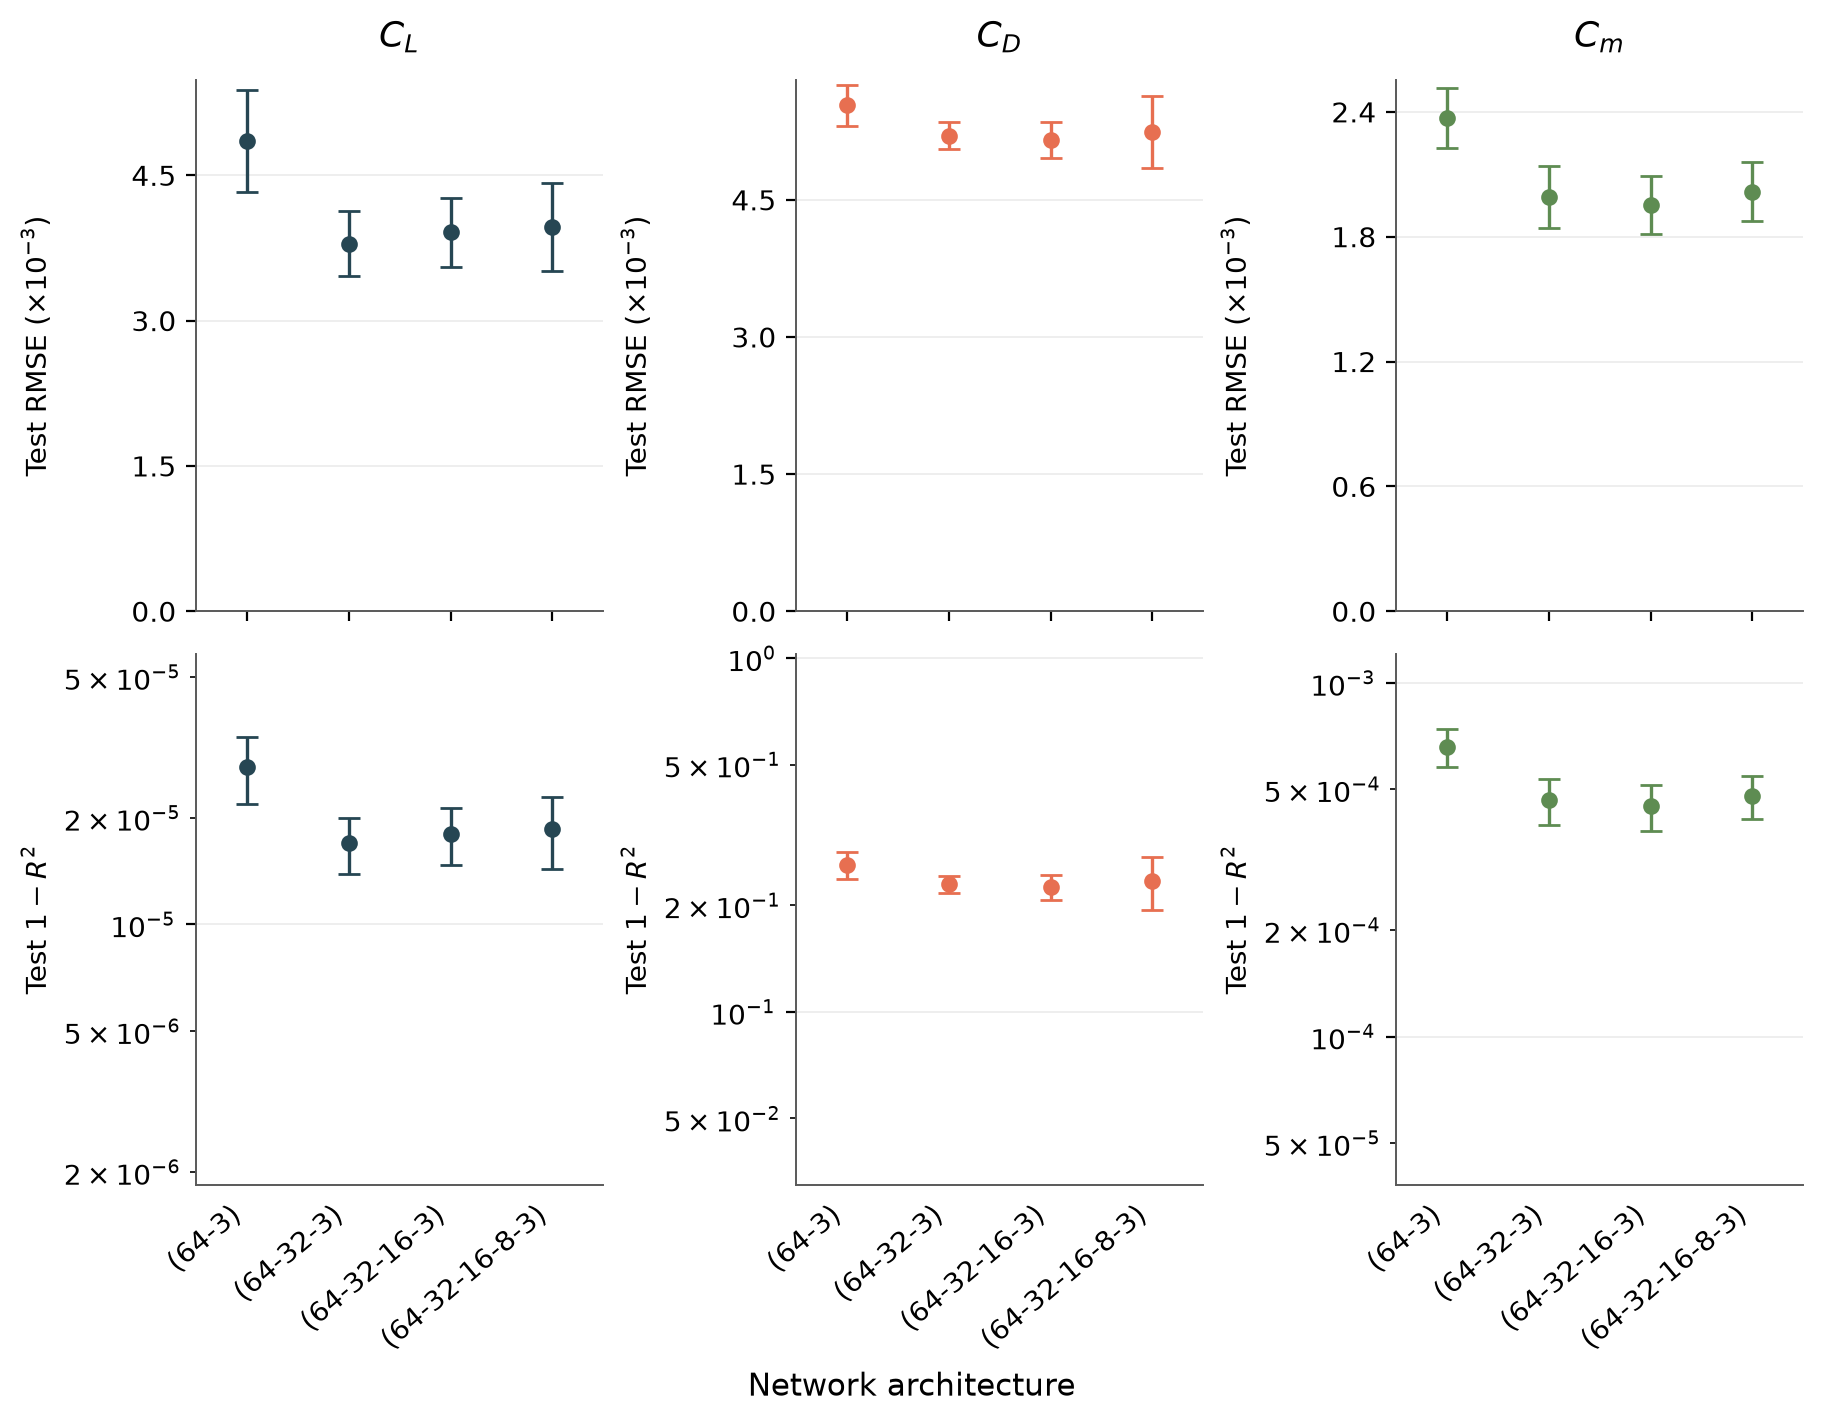

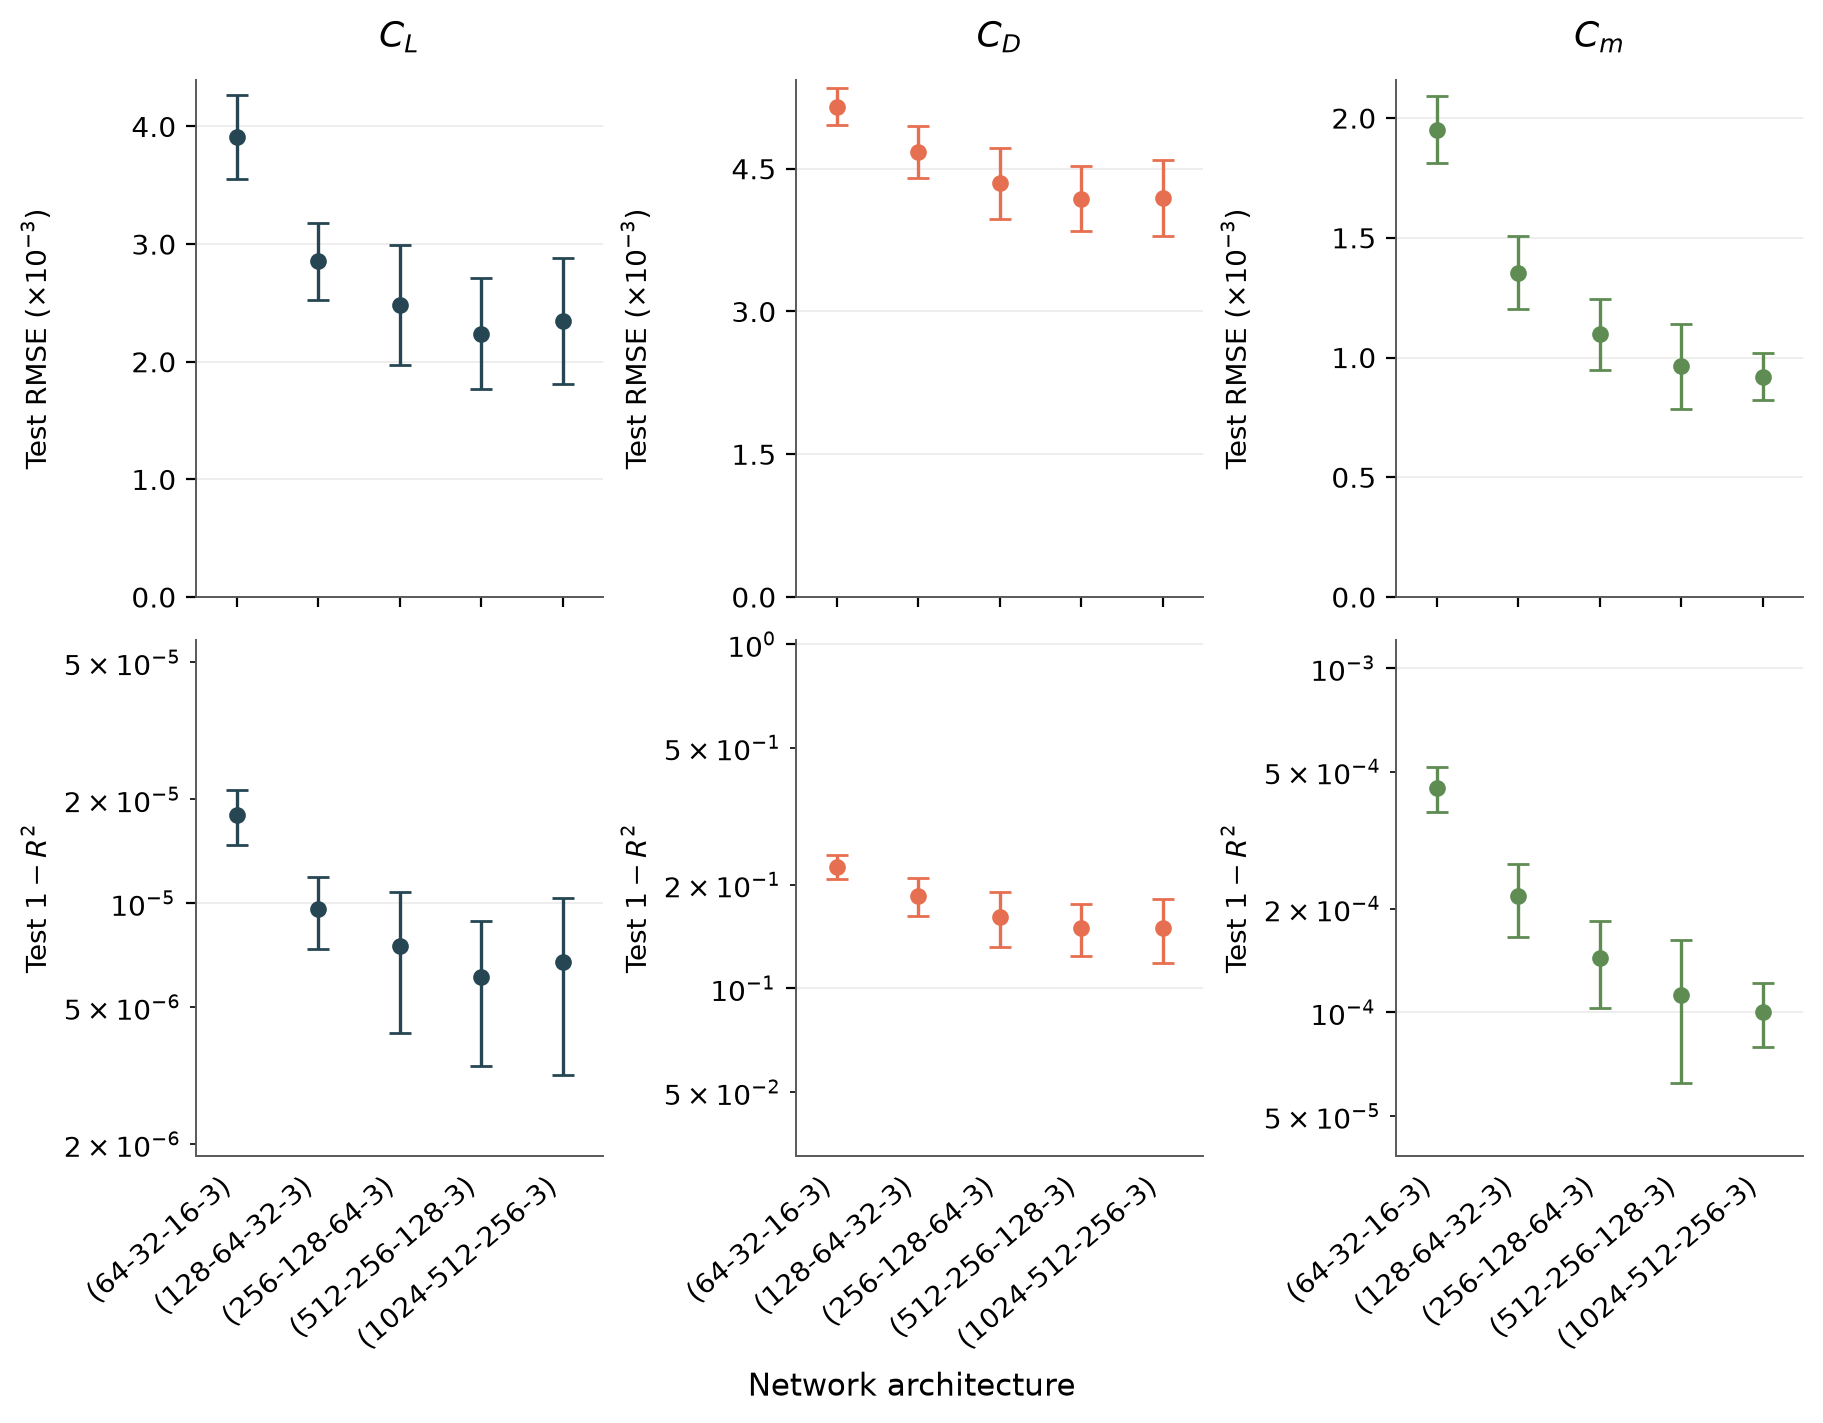

In [25]:
# Compare test RMSE and R² across network architectures
from matplotlib.ticker import FormatStrFormatter, LogFormatterSciNotation, LogLocator

# Separate depth and width experiments; the shared baseline appears in both.
if "DEPTH_ARCHITECTURES" in globals():
    plot_groups = [
        ("depth", globals()["DEPTH_ARCHITECTURES"]),
        ("width", globals()["WIDTH_ARCHITECTURES"]),
    ]
else:
    plot_groups = [(None, ARCHITECTURES)]
# Update the learning curves to use shared axis limits
loss_limits = learning_curve_limits()
for group, names in plot_groups:
    for name in names:
        show_learning_curve(name, group or "training", loss_limits)
for group, names in plot_groups:
    fig, axes = plt.subplots(2, 3, figsize=(9, 7), sharex=True)
    x = np.arange(len(names))
    for j, (target, symbol, color) in enumerate(
        zip(TARGETS, [r"$C_L$", r"$C_D$", r"$C_m$"], ["#264653", "#E76F51", "#5E8C52"])
    ):
        for row, suffix, ylabel in [
            (0, "rmse", "Test RMSE"),
            (1, "r2", r"Test $1 - R^2$"),
        ]:
            ax = axes[row, j]
            values = [metrics[name][f"{target}_{suffix}"] for name in names]
            if row == 1:
                values = [1 - v for v in values]
            means = np.array([v.mean() for v in values])
            deviations = np.array([v.std(ddof=1) if len(v) > 1 else 0 for v in values])
            if row == 0:
                means = means * 1e3
                deviations = deviations * 1e3
                ylabel = r"Test RMSE ($\times 10^{-3}$)"
            ax.errorbar(
                x,
                means,
                yerr=deviations,
                fmt="o",
                color=color,
                markersize=5,
                capsize=4,
                linewidth=1.2,
            )
            ax.set_ylabel(ylabel)
            ax.set_xlim(-0.5, len(names) - 0.5)
            ax.grid(axis="y", color="0.92", linewidth=0.6)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            if row == 0:
                ax.set_title(symbol, fontsize=13, pad=12)
                ax.set_ylim(bottom=0)
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
            else:
                if np.any(means <= 0):
                    raise ValueError(
                        "Logarithmic 1 − R² plots require positive mean errors"
                    )
                # Use the same limits for depth and width; retain all mean ± SD bars.
                error_runs = [
                    1 - metrics[name][f"{target}_r2"] for name in ARCHITECTURES
                ]
                error_means = np.array([v.mean() for v in error_runs])
                error_sd = np.array(
                    [v.std(ddof=1) if len(v) > 1 else 0 for v in error_runs]
                )
                positive_errors = np.concatenate(
                    [v[v > 0].to_numpy() for v in error_runs]
                )
                lower = np.min(error_means - error_sd)
                if lower <= 0:
                    lower = positive_errors.min()
                upper = np.max(error_means + error_sd)
                log_low, log_high = np.log10([lower, upper])
                center = (log_low + log_high) / 2
                half_span = max(0.75, (log_high - log_low) / 2 + 0.08)
                ax.set_yscale("log")
                ax.set_ylim(10 ** (center - half_span), 10 ** (center + half_span))
                ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1,), numticks=10))
                ax.yaxis.set_minor_locator(
                    LogLocator(base=10, subs=(2, 5), numticks=20)
                )
                for which in ["major", "minor"]:
                    formatter = LogFormatterSciNotation(
                        base=10, labelOnlyBase=False, minor_thresholds=(np.inf, np.inf)
                    )
                    if which == "major":
                        ax.yaxis.set_major_formatter(formatter)
                    else:
                        ax.yaxis.set_minor_formatter(formatter)
                ax.tick_params(axis="y", which="minor", labelsize=10)
                ax.set_xticks(
                    x,
                    [architecture(name) for name in names],
                    rotation=40,
                    ha="right",
                    fontsize=10,
                )
                ax.tick_params(axis="x", length=0, pad=6)
    fig.supxlabel("Network architecture", fontsize=11)
    fig.align_ylabels()
    comparison = (
        f"{group.capitalize()} comparison" if group else "Architecture comparison"
    )
    finish_figure(
        fig,
        f"architecture-metrics-{group}" if group else "architecture-metrics",
        caption=f"{comparison}. Test RMSE and 1 − R²: mean ± SD across {N_RUNS} independent training runs (random seeds). "
        "RMSE values are shown in units of 10⁻³. The 1 − R² axis is logarithmic; lower values indicate better predictions.",
    )

## Results Export

In [26]:
# Save per-seed metrics and dataset row identifiers
experiment_results.export_results(
    ROOT,
    NOTEBOOK_NAME,
    DATASETS,
    {"train": X_train.index, "validation": X_val.index, "test": X_test.index},
    metrics,
    validation_metrics,
    histories,
    experiment_results.training_settings(N_RUNS, EPOCHS, y_train, "single-family-row"),
)